In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/CarWise_raw.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nPrice Statistics:")
display(df["price"].describe())

Matplotlib is building the font cache; this may take a moment.


Dataset Shape: (8249, 528)

First 5 Rows:


,transmission,ownerNo,modelYear,price,Kms Driven,Mileage,Seats,Fuel type_Diesel,Fuel type_Electric,Fuel type_Lpg,...,Color_g brown,Color_golden brown,Color_m grey,Color_magma gray,Color_urban titanim,City_Chennai,City_Delhi,City_Hyderabad,City_Jaipur,City_Kolkata
0,1,2.577392,-0.391413,400000.0,0.819543,1.001444,-0.305294,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,1.008900,0.379360,811000.0,-0.352937,-0.587173,-0.305294,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,-0.559592,0.379360,585000.0,-0.631733,1.194161,-0.305294,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,-0.559592,-0.648338,462000.0,-0.553226,-0.040272,-0.305294,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,-0.559592,-0.391413,790000.0,0.013659,1.144680,-0.305294,1,0,0,...,0,0,0,0,0,0,0,0,0,0



Missing Values: 0
Duplicate Rows: 0

Price Statistics:


count    8.249000e+03
mean     9.587665e+05
std      1.420438e+06
min      2.800000e+04
25%      4.000000e+05
50%      6.020000e+05
75%      9.500000e+05
max      4.150000e+07
Name: price, dtype: float64

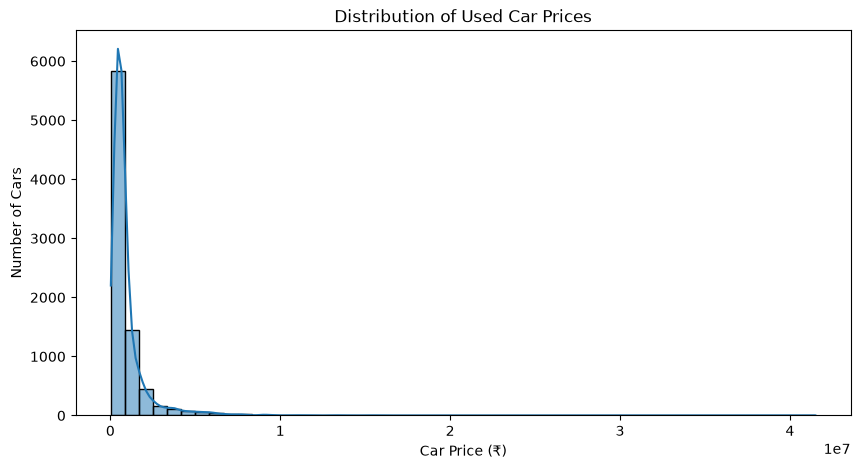

In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=50, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Car Price (₹)")
plt.ylabel("Number of Cars")
plt.show()

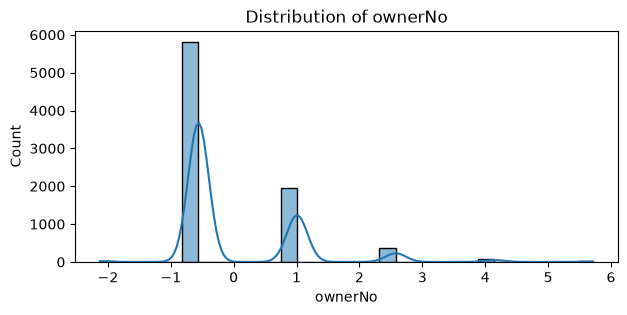

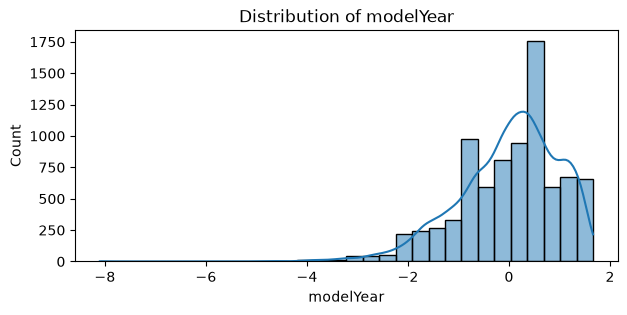

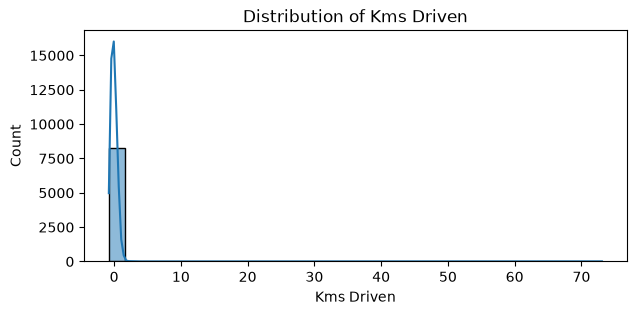

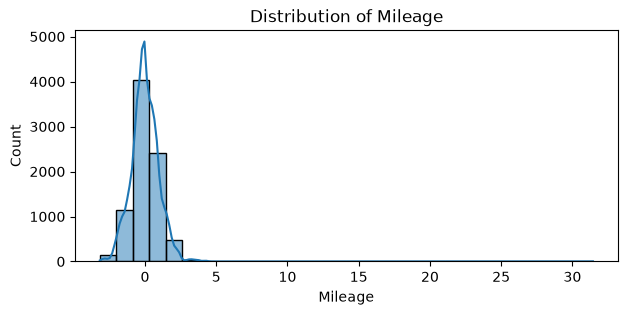

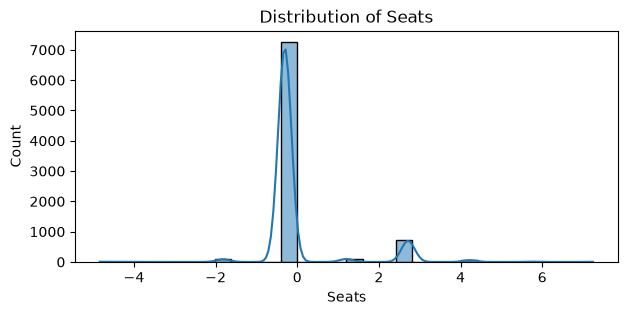

In [3]:
features = ["ownerNo", "modelYear", "Kms Driven", "Mileage", "Seats"]

for col in features:
    plt.figure(figsize=(7, 3))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [4]:
correlations = df.corr(numeric_only=True)["price"].drop("price")

top_features = correlations.abs().sort_values(ascending=False).head(15)

print("Top 15 Features Related to Car Price:")
display(
    pd.DataFrame({
        "Feature": top_features.index,
        "Correlation": correlations[top_features.index].values
    })
)

Top 15 Features Related to Car Price:


,Feature,Correlation
0,model_Mercedes-Benz AMG G 63,0.433532
1,transmission,-0.422787
2,Brand_Mercedes-Benz,0.405415
3,body type_Hatchback,-0.310376
4,modelYear,0.299011
5,body type_SUV,0.290871
6,Mileage,-0.270653
7,Brand_BMW,0.268901
8,Brand_Land Rover,0.243308
9,model_Toyota Land Cruiser 300,0.201104


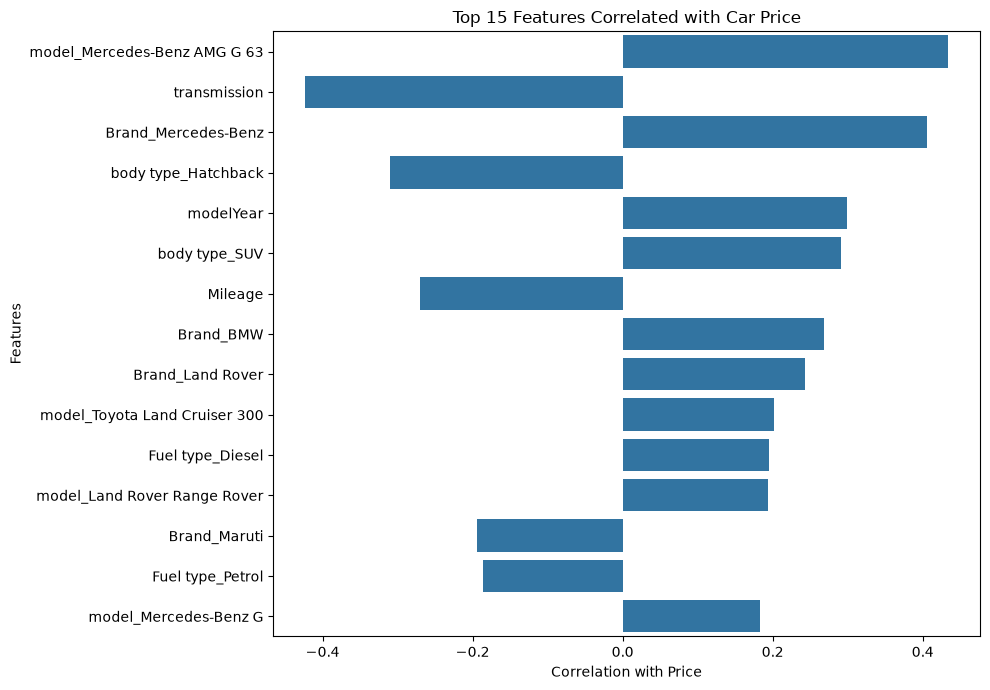

In [5]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=correlations[top_features.index].values,
    y=top_features.index
)

plt.title("Top 15 Features Correlated with Car Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

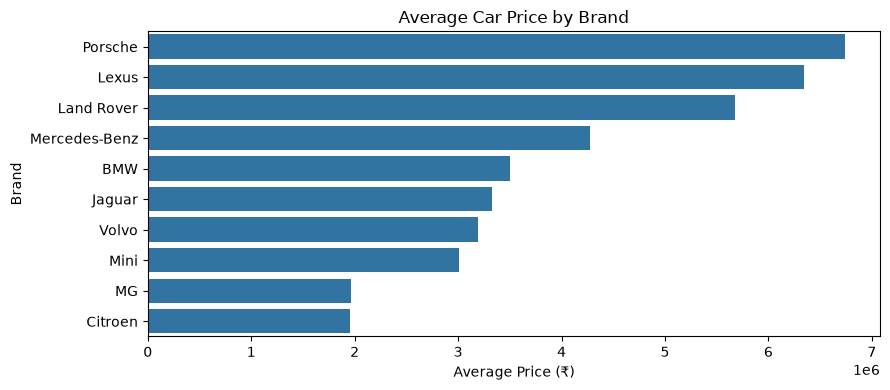

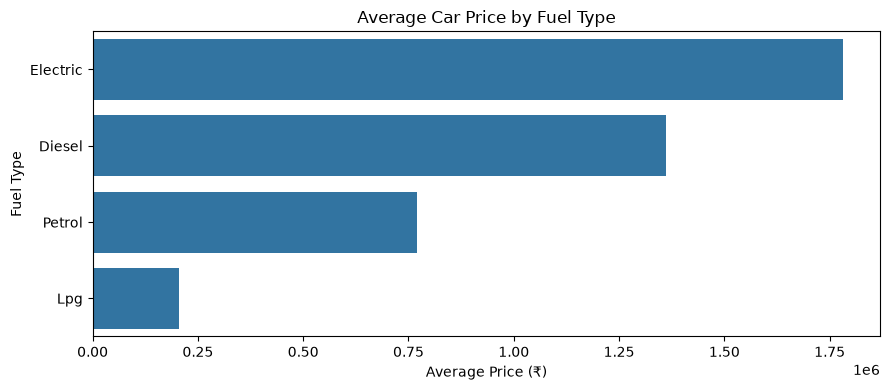

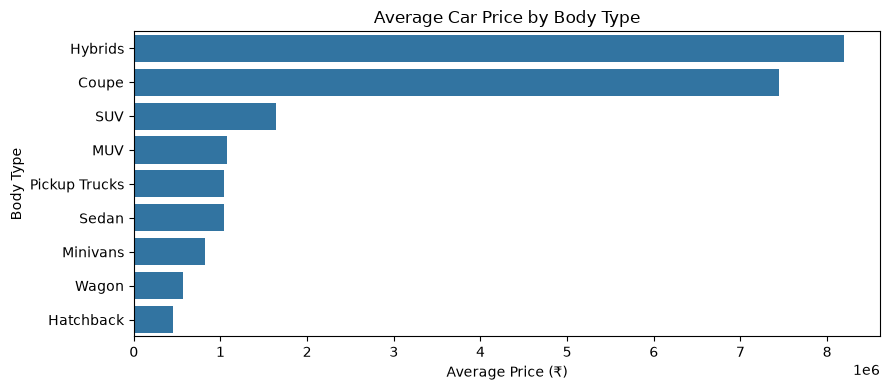

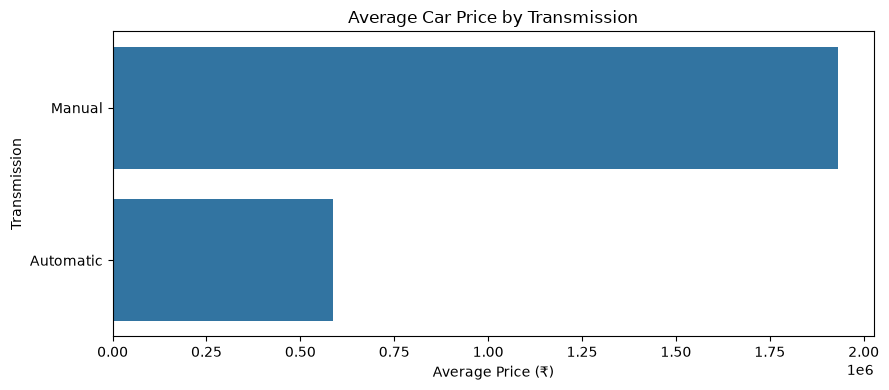

In [6]:
groups = {
    "Brand": "Brand_",
    "Fuel Type": "Fuel type_",
    "Body Type": "body type_",
    "Transmission": "transmission"
}

for name, prefix in groups.items():
    if prefix == "transmission":
        temp = df.groupby("transmission")["price"].mean()
        temp.index = ["Automatic" if x == 1 else "Manual" for x in temp.index]
    else:
        columns = [c for c in df.columns if c.startswith(prefix)]
        temp = pd.Series({
            col.replace(prefix, ""): df.loc[df[col] == 1, "price"].mean()
            for col in columns
        }).sort_values(ascending=False).head(10)

    plt.figure(figsize=(9, 4))
    sns.barplot(x=temp.values, y=temp.index)
    plt.title(f"Average Car Price by {name}")
    plt.xlabel("Average Price (₹)")
    plt.ylabel(name)
    plt.tight_layout()
    plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop("price", axis=1)
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training records: 6599
Testing records: 1650
Number of features: 527


In [8]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression training completed!")

Linear Regression training completed!


In [9]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [10]:
from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=700,
    depth=8,
    learning_rate=0.05,
    loss_function="RMSE",
    verbose=100,
    random_seed=42
)

cat_model.fit(X_train, y_train)

cat_predictions = cat_model.predict(X_test)

print("CatBoost training completed!")

0:	learn: 1306782.0120835	total: 155ms	remaining: 1m 48s
100:	learn: 636111.7560827	total: 1.58s	remaining: 9.37s
200:	learn: 421368.4229496	total: 3.22s	remaining: 8s
300:	learn: 331935.7835545	total: 5.13s	remaining: 6.81s
400:	learn: 276393.7641162	total: 6s	remaining: 4.48s
500:	learn: 237645.4961207	total: 6.56s	remaining: 2.6s
600:	learn: 211851.6507753	total: 7.13s	remaining: 1.18s
699:	learn: 191373.3732434	total: 7.72s	remaining: 0us
CatBoost training completed!


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions,
    "CatBoost": cat_predictions
}

results = []

for name, predictions in models.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("RMSE"))

,Model,MAE,RMSE,R2 Score
2,CatBoost,177675.62,585741.51,0.8829
1,Random Forest,170550.50,660116.14,0.8513
0,Linear Regression,261069.51,724250.30,0.8210


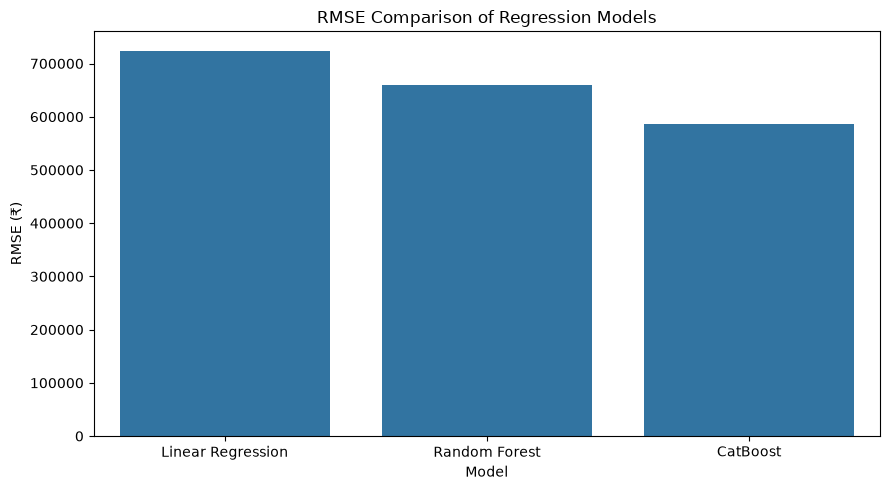

In [12]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("RMSE Comparison of Regression Models")
plt.ylabel("RMSE (₹)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

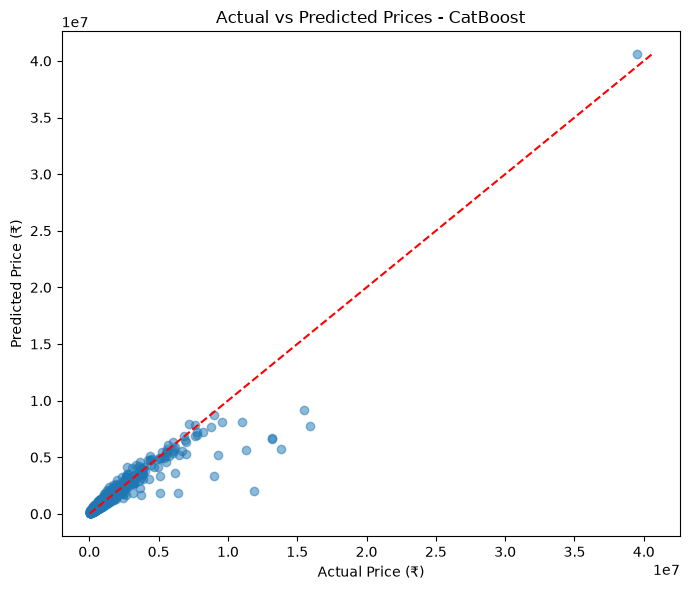

Best model: CatBoost


In [13]:
best_model_name = results_df.sort_values("RMSE").iloc[0]["Model"]

prediction_map = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions,
    "CatBoost": cat_predictions
}

best_predictions = prediction_map[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.5)
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title(f"Actual vs Predicted Prices - {best_model_name}")

min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot([min_price, max_price], [min_price, max_price], "r--")
plt.tight_layout()
plt.show()

print("Best model:", best_model_name)

In [14]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(linear_model, "../models/linear_regression.pkl")
joblib.dump(rf_model, "../models/random_forest.pkl")
joblib.dump(cat_model, "../models/catboost_model.pkl")

print("All three models saved successfully!")

All three models saved successfully!


In [15]:
results_df.to_csv("../models/model_comparison.csv", index=False)
print("Results saved successfully!")

Results saved successfully!
